# 05 — EV Charging High-Demand Classification

## Objective
Build machine-learning classifiers to predict whether a charging session belongs to the High Demand or Normal Demand category.

## Target Definition
Following the GUVI project rule:
- **High Demand:** `Demand >= median(Demand)`
- **Normal Demand:** `Demand < median(Demand)`

Notebook 02 created the `DemandCategory` target using the dataset median of 14.1. This notebook will use that existing target.

## Experiment Design
Compare five classifiers:
1. Logistic Regression
2. Decision Tree
3. Random Forest
4. XGBoost
5. LightGBM

Evaluate two feature configurations:
- **Without Duration:** uses location, charger type, charging company, and temporal features.
- **With Duration:** adds `DurationValidated` to the same predictors.

Use a chronological train-test split and consistent preprocessing pipelines.

## Evaluation Metrics
- Accuracy
- Precision
- Recall
- F1-score
- ROC-AUC
- Confusion matrix

A majority-class baseline will be included for reference.

## Methodological Notes
- `DemandCategory` is the target; `Demand` itself must not be a predictor.
- User and charger identifiers are excluded from the initial feature set.
- Missing duration values will be imputed within the training pipeline.
- Oversampling will not be applied automatically because the original target classes are nearly balanced.
- Actual duration is not available at session start. Duration-based results must be interpreted accordingly.

In [1]:
from pathlib import Path
import time

import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

# Paths are relative to the notebooks/ folder.
DATA_PATH = Path("../data/processed/ev_charging_features.csv")
RANDOM_STATE = 42
TEST_SIZE = 0.20

# Stop early if the expected dataset cannot be found.
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found: {DATA_PATH.resolve()}"
    )

# Load the dataset produced by Notebook 02.
df = pd.read_csv(DATA_PATH)

# Parse timestamps for chronological splitting.
df["StartDatetime"] = pd.to_datetime(
    df["StartDatetime"],
    errors="coerce",
)

# Preserve company and charger type codes as categories.
for col in ["ChargerCompany", "ChargerType"]:
    df[col] = df[col].astype(str)

print("Dataset loaded successfully.")
print("Dataset shape:", df.shape)
print("Start date:", df["StartDatetime"].min())
print("End date:", df["StartDatetime"].max())

Dataset loaded successfully.
Dataset shape: (72826, 24)
Start date: 2021-09-30 17:14:26
End date: 2022-09-30 23:11:59


In [2]:
# Columns needed for this classification experiment.
required_columns = [
    "StartDatetime",
    "Demand",
    "DemandCategory",
    "Location",
    "ChargerCompany",
    "ChargerType",
    "StartDayName",
    "TimeOfDay",
    "StartMonth",
    "StartDayOfMonth",
    "StartHour",
    "IsWeekend",
    "DurationValidated",
]

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Required columns are missing: {missing_columns}"
    )

# Check the integrity of timestamps and labels before splitting.
print("Exact duplicate rows:", df.duplicated().sum())
print("Missing timestamps:", df["StartDatetime"].isna().sum())
print("Missing Demand values:", df["Demand"].isna().sum())
print("Missing classification labels:", df["DemandCategory"].isna().sum())
print(
    "Missing validated duration:",
    df["DurationValidated"].isna().sum(),
)

# Confirm that only the expected two class labels exist.
expected_classes = {"High Demand", "Normal Demand"}

observed_classes = set(
    df["DemandCategory"].dropna().unique()
)

if observed_classes != expected_classes:
    raise ValueError(
        f"Unexpected classification labels: {observed_classes}"
    )

print("\nClass distribution:")
class_counts = df["DemandCategory"].value_counts()

class_summary = pd.DataFrame({
    "Count": class_counts,
    "Percentage": class_counts / len(df) * 100,
})

display(class_summary.round(2))

Exact duplicate rows: 0
Missing timestamps: 0
Missing Demand values: 0
Missing classification labels: 0
Missing validated duration: 3376

Class distribution:


,Count,Percentage
DemandCategory,,
High Demand,36439,50.04
Normal Demand,36387,49.96


In [3]:
# Define the categorical features shared by both experiments.
categorical_features = [
    "Location",
    "ChargerCompany",
    "ChargerType",
    "StartDayName",
    "TimeOfDay",
]

# Numerical predictors for the model without duration.
numeric_features_without_duration = [
    "StartMonth",
    "StartDayOfMonth",
    "StartHour",
    "IsWeekend",
]

# The second experiment adds validated duration.
numeric_features_with_duration = (
    numeric_features_without_duration
    + ["DurationValidated"]
)

# Define the two feature configurations.
features_without_duration = (
    categorical_features
    + numeric_features_without_duration
)

features_with_duration = (
    categorical_features
    + numeric_features_with_duration
)

# Sort sessions chronologically before splitting.
df = (
    df.sort_values("StartDatetime")
      .reset_index(drop=True)
)

# Encode classes as integers for compatibility across classifiers:
# 0 = Normal Demand, 1 = High Demand.
target_mapping = {
    "Normal Demand": 0,
    "High Demand": 1,
}

y = df["DemandCategory"].map(target_mapping)

if y.isna().any():
    raise ValueError("Unexpected or missing classification labels.")

y = y.astype(int)

# Build the two feature matrices.
X_without_duration = df[features_without_duration].copy()
X_with_duration = df[features_with_duration].copy()

# Use the same approximate 80/20 chronological boundary as regression.
split_index = int(len(df) * (1 - TEST_SIZE))
split_datetime = df.loc[split_index, "StartDatetime"]

# Keep all records with the same boundary timestamp in one split.
train_mask = df["StartDatetime"] < split_datetime
test_mask = df["StartDatetime"] >= split_datetime

X_train_without = X_without_duration.loc[train_mask]
X_test_without = X_without_duration.loc[test_mask]

X_train_with = X_with_duration.loc[train_mask]
X_test_with = X_with_duration.loc[test_mask]

y_train = y.loc[train_mask]
y_test = y.loc[test_mask]

# Verify both experiments use identical observations.
assert X_train_without.index.equals(X_train_with.index)
assert X_test_without.index.equals(X_test_with.index)
assert y_train.index.equals(X_train_with.index)
assert y_test.index.equals(X_test_with.index)

print("Chronological split completed.")
print(f"Boundary timestamp: {split_datetime}")
print(f"Training rows: {len(y_train):,}")
print(f"Testing rows: {len(y_test):,}")

print("\nTraining period:")
print(df.loc[train_mask, "StartDatetime"].min())
print(df.loc[train_mask, "StartDatetime"].max())

print("\nTesting period:")
print(df.loc[test_mask, "StartDatetime"].min())
print(df.loc[test_mask, "StartDatetime"].max())

# Inspect the class balance separately in each period.
class_names = {
    0: "Normal Demand",
    1: "High Demand",
}

for split_name, labels in [
    ("Training", y_train),
    ("Testing", y_test),
]:
    counts = labels.map(class_names).value_counts()
    percentages = (
        labels.map(class_names)
        .value_counts(normalize=True)
        .mul(100)
    )

    print(f"\n{split_name} class distribution:")

    display(pd.DataFrame({
        "Count": counts,
        "Percentage": percentages.round(2),
    }))

Chronological split completed.
Boundary timestamp: 2022-07-30 19:09:37
Training rows: 58,260
Testing rows: 14,566

Training period:
2021-09-30 17:14:26
2022-07-30 19:09:27

Testing period:
2022-07-30 19:09:37
2022-09-30 23:11:59

Training class distribution:


,Count,Percentage
DemandCategory,,
High Demand,29302,50.3
Normal Demand,28958,49.7



Testing class distribution:


,Count,Percentage
DemandCategory,,
Normal Demand,7429,51.0
High Demand,7137,49.0


In [4]:
def make_preprocessor(numeric_features):
    """
    Build preprocessing for categorical and numeric predictors.

    Categorical: impute missing values, then one-hot encode.
    Numeric: impute with median, then standardize.
    """
    categorical_transformer = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False,
            ),
        ),
    ])

    numeric_transformer = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ])

    return ColumnTransformer(
        transformers=[
            (
                "categorical",
                categorical_transformer,
                categorical_features,
            ),
            (
                "numeric",
                numeric_transformer,
                numeric_features,
            ),
        ],
        remainder="drop",
    )


# Keep both experiments comparable.
experiments = {
    "Without Duration": {
        "X_train": X_train_without,
        "X_test": X_test_without,
        "numeric_features": numeric_features_without_duration,
    },
    "With Duration": {
        "X_train": X_train_with,
        "X_test": X_test_with,
        "numeric_features": numeric_features_with_duration,
    },
}

print("Preprocessing pipelines defined.")
print("Feature configurations:", list(experiments))

Preprocessing pipelines defined.
Feature configurations: ['Without Duration', 'With Duration']


In [5]:
from sklearn.base import clone

classifiers = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=RANDOM_STATE,
    ),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=15,
        min_samples_leaf=10,
        random_state=RANDOM_STATE,
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        max_depth=20,
        min_samples_leaf=2,
        n_jobs=-1,
        random_state=RANDOM_STATE,
    ),

    "XGBoost": XGBClassifier(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=6,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_lambda=1.0,
        objective="binary:logistic",
        eval_metric="logloss",
        tree_method="hist",
        n_jobs=-1,
        random_state=RANDOM_STATE,
    ),

    "LightGBM": LGBMClassifier(
        n_estimators=300,
        learning_rate=0.05,
        num_leaves=31,
        colsample_bytree=0.8,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        verbosity=-1,
    ),
}

print(f"Number of classifiers: {len(classifiers)}")
print("Models:", list(classifiers.keys()))

Number of classifiers: 5
Models: ['Logistic Regression', 'Decision Tree', 'Random Forest', 'XGBoost', 'LightGBM']


In [6]:
results = []
fitted_pipelines = {}
test_predictions = {}
test_probabilities = {}
confusion_matrices = {}

for feature_set, experiment in experiments.items():
    print(f"\n{'=' * 55}")
    print(f"Feature configuration: {feature_set}")
    print(f"{'=' * 55}")

    for model_name, model in classifiers.items():
        pipeline = Pipeline(steps=[
            (
                "preprocessor",
                make_preprocessor(
                    experiment["numeric_features"]
                ),
            ),
            ("model", clone(model)),
        ])

        start_time = time.perf_counter()

        # Fit preprocessing and classifier on training records only.
        pipeline.fit(
            experiment["X_train"],
            y_train,
        )

        fit_seconds = time.perf_counter() - start_time

        # Predict class labels and probabilities on later records.
        y_pred = pipeline.predict(experiment["X_test"])
        y_prob = pipeline.predict_proba(
            experiment["X_test"]
        )[:, 1]

        # Class 1 means High Demand.
        results.append({
            "FeatureSet": feature_set,
            "Model": model_name,
            "Accuracy": accuracy_score(y_test, y_pred),
            "Precision": precision_score(
                y_test, y_pred, pos_label=1, zero_division=0
            ),
            "Recall": recall_score(
                y_test, y_pred, pos_label=1, zero_division=0
            ),
            "F1": f1_score(
                y_test, y_pred, pos_label=1, zero_division=0
            ),
            "ROC_AUC": roc_auc_score(y_test, y_prob),
            "FitSeconds": fit_seconds,
        })

        key = (feature_set, model_name)
        fitted_pipelines[key] = pipeline
        test_predictions[key] = y_pred
        test_probabilities[key] = y_prob

        # Fixed label order:
        # 0 = Normal Demand, 1 = High Demand.
        confusion_matrices[key] = confusion_matrix(
            y_test,
            y_pred,
            labels=[0, 1],
        )

        print(
            f"{model_name}: "
            f"Accuracy={accuracy_score(y_test, y_pred):.4f}, "
            f"F1={f1_score(y_test, y_pred, zero_division=0):.4f}, "
            f"ROC-AUC={roc_auc_score(y_test, y_prob):.4f}"
        )

results_df = (
    pd.DataFrame(results)
    .sort_values("F1", ascending=False)
    .reset_index(drop=True)
)

display(results_df.round(4))


Feature configuration: Without Duration
Logistic Regression: Accuracy=0.6344, F1=0.6377, ROC-AUC=0.6690
Decision Tree: Accuracy=0.6085, F1=0.5869, ROC-AUC=0.6482
Random Forest: Accuracy=0.6349, F1=0.6410, ROC-AUC=0.6755
XGBoost: Accuracy=0.6370, F1=0.6591, ROC-AUC=0.6798
LightGBM: Accuracy=0.6468, F1=0.6662, ROC-AUC=0.6910

Feature configuration: With Duration
Logistic Regression: Accuracy=0.8422, F1=0.8463, ROC-AUC=0.8936
Decision Tree: Accuracy=0.8578, F1=0.8600, ROC-AUC=0.9215
Random Forest: Accuracy=0.8696, F1=0.8745, ROC-AUC=0.9366
XGBoost: Accuracy=0.8696, F1=0.8744, ROC-AUC=0.9419
LightGBM: Accuracy=0.8720, F1=0.8774, ROC-AUC=0.9448


,FeatureSet,Model,Accuracy,Precision,Recall,F1,ROC_AUC,FitSeconds
0,With Duration,LightGBM,0.8720,0.8267,0.9347,0.8774,0.9448,0.4176
1,With Duration,Random Forest,0.8696,0.8275,0.9273,0.8745,0.9366,0.4900
2,With Duration,XGBoost,0.8696,0.8279,0.9264,0.8744,0.9419,0.5566
3,With Duration,Decision Tree,0.8578,0.8309,0.8913,0.8600,0.9215,0.2600
4,With Duration,Logistic Regression,0.8422,0.8095,0.8866,0.8463,0.8936,0.2191
5,Without Duration,LightGBM,0.6468,0.6203,0.7195,0.6662,0.6910,3.0118
6,Without Duration,XGBoost,0.6370,0.6104,0.7161,0.6591,0.6798,0.4938
7,Without Duration,Random Forest,0.6349,0.6185,0.6653,0.6410,0.6755,0.4964
8,Without Duration,Logistic Regression,0.6344,0.6197,0.6567,0.6377,0.6690,0.2466
9,Without Duration,Decision Tree,0.6085,0.6077,0.5675,0.5869,0.6482,0.2325


In [7]:
from sklearn.dummy import DummyClassifier

# Readable label names for encoded classes:
# 0 = Normal Demand, 1 = High Demand.
class_labels = ["Normal Demand", "High Demand"]

# Examine the two LightGBM configurations.
for feature_set in ["Without Duration", "With Duration"]:
    print(f"\n{'=' * 55}")
    print(f"LightGBM — {feature_set}")
    print(f"{'=' * 55}")

    # Rows represent actual labels; columns represent predictions.
    cm = confusion_matrices[(feature_set, "LightGBM")]

    confusion_df = pd.DataFrame(
        cm,
        index=[f"Actual {label}" for label in class_labels],
        columns=[f"Predicted {label}" for label in class_labels],
    )

    display(confusion_df)

    print("\nClassification report:")
    print(
        classification_report(
            y_test,
            test_predictions[(feature_set, "LightGBM")],
            labels=[0, 1],
            target_names=class_labels,
            digits=4,
            zero_division=0,
        )
    )


# Baseline: always predict the majority class in training data.
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train_without, y_train)

baseline_pred = baseline.predict(X_test_without)
baseline_prob = baseline.predict_proba(X_test_without)[:, 1]

baseline_metrics = {
    "Model": "Majority-Class Baseline",
    "Accuracy": accuracy_score(y_test, baseline_pred),
    "Precision": precision_score(
        y_test, baseline_pred, zero_division=0
    ),
    "Recall": recall_score(
        y_test, baseline_pred, zero_division=0
    ),
    "F1": f1_score(
        y_test, baseline_pred, zero_division=0
    ),
    "ROC_AUC": roc_auc_score(y_test, baseline_prob),
}

print("\nBaseline metrics:")
display(pd.DataFrame([baseline_metrics]).round(4))

print("\nBaseline confusion matrix:")
display(pd.DataFrame(
    confusion_matrix(y_test, baseline_pred, labels=[0, 1]),
    index=[f"Actual {label}" for label in class_labels],
    columns=[f"Predicted {label}" for label in class_labels],
))


LightGBM — Without Duration


,Predicted Normal Demand,Predicted High Demand
Actual Normal Demand,4286,3143
Actual High Demand,2002,5135



Classification report:
               precision    recall  f1-score   support

Normal Demand     0.6816    0.5769    0.6249      7429
  High Demand     0.6203    0.7195    0.6662      7137

     accuracy                         0.6468     14566
    macro avg     0.6510    0.6482    0.6456     14566
 weighted avg     0.6516    0.6468    0.6452     14566


LightGBM — With Duration


,Predicted Normal Demand,Predicted High Demand
Actual Normal Demand,6031,1398
Actual High Demand,466,6671



Classification report:
               precision    recall  f1-score   support

Normal Demand     0.9283    0.8118    0.8661      7429
  High Demand     0.8267    0.9347    0.8774      7137

     accuracy                         0.8720     14566
    macro avg     0.8775    0.8733    0.8718     14566
 weighted avg     0.8785    0.8720    0.8717     14566


Baseline metrics:


,Model,Accuracy,Precision,Recall,F1,ROC_AUC
0,Majority-Class Baseline,0.49,0.49,1.0,0.6577,0.5



Baseline confusion matrix:


,Predicted Normal Demand,Predicted High Demand
Actual Normal Demand,0,7429
Actual High Demand,0,7137


In [9]:
import joblib
import json
from pathlib import Path

# Create output directories if they do not already exist.
MODELS_DIR = Path("../models")
REPORTS_DIR = Path("../reports")

MODELS_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

# Retrieve the fitted LightGBM pipelines from the experiment.
lgbm_with_duration = fitted_pipelines[
    ("With Duration", "LightGBM")
]

lgbm_without_duration = fitted_pipelines[
    ("Without Duration", "LightGBM")
]

# Save both pipelines, including their fitted preprocessing steps.
joblib.dump(
    lgbm_with_duration,
    MODELS_DIR / "lightgbm_classifier_with_duration_pipeline.joblib",
)

joblib.dump(
    lgbm_without_duration,
    MODELS_DIR / "lightgbm_classifier_without_duration_pipeline.joblib",
)

# Save the complete classification model comparison.
results_df.to_csv(
    REPORTS_DIR / "classification_model_comparison_chronological.csv",
    index=False,
)

# Save baseline metrics.
pd.DataFrame([baseline_metrics]).to_csv(
    REPORTS_DIR / "classification_baseline_metrics.csv",
    index=False,
)

# Save the LightGBM confusion matrices with readable labels.
class_names = ["Normal Demand", "High Demand"]

for feature_set, filename in [
    ("Without Duration", "classification_confusion_matrix_without_duration.csv"),
    ("With Duration", "classification_confusion_matrix_with_duration.csv"),
]:
    cm = confusion_matrices[(feature_set, "LightGBM")]

    cm_df = pd.DataFrame(
        cm,
        index=[f"Actual {name}" for name in class_names],
        columns=[f"Predicted {name}" for name in class_names],
    )

    cm_df.to_csv(REPORTS_DIR / filename)

# Save held-out test predictions and probabilities.
actual_labels = y_test.map({
    0: "Normal Demand",
    1: "High Demand",
}).to_numpy()

prediction_df = pd.DataFrame({
    "StartDatetime": df.loc[test_mask, "StartDatetime"].to_numpy(),
    "ActualDemandCategory": actual_labels,
})

for feature_set, suffix in [
    ("Without Duration", "WithoutDuration"),
    ("With Duration", "WithDuration"),
]:
    pred = test_predictions[(feature_set, "LightGBM")]
    prob = test_probabilities[(feature_set, "LightGBM")]

    prediction_df[f"PredictedCategory_{suffix}"] = np.where(
        pred == 1,
        "High Demand",
        "Normal Demand",
    )

    prediction_df[f"HighDemandProbability_{suffix}"] = prob

prediction_df.to_csv(
    REPORTS_DIR / "classification_test_predictions.csv",
    index=False,
)

# Save model interpretation metadata for future application use.
metadata = {
    "target": "DemandCategory",
    "label_mapping": {
        "0": "Normal Demand",
        "1": "High Demand",
    },
    "models": {
        "with_duration": "lightgbm_classifier_with_duration_pipeline.joblib",
        "without_duration": "lightgbm_classifier_without_duration_pipeline.joblib",
    },
    "split_strategy": "Chronological 80/20 split",
    "test_size": int(len(y_test)),
    "duration_note": (
        "Actual validated duration is available only after a session ends. "
        "Do not treat the duration-based model as a session-start model."
    ),
}

with open(
    REPORTS_DIR / "classification_model_metadata.json",
    "w",
    encoding="utf-8",
) as file:
    json.dump(metadata, file, indent=4)

# Verify that the expected artifacts exist and are non-empty.
saved_files = [
    MODELS_DIR / "lightgbm_classifier_with_duration_pipeline.joblib",
    MODELS_DIR / "lightgbm_classifier_without_duration_pipeline.joblib",
    REPORTS_DIR / "classification_model_comparison_chronological.csv",
    REPORTS_DIR / "classification_baseline_metrics.csv",
    REPORTS_DIR / "classification_confusion_matrix_without_duration.csv",
    REPORTS_DIR / "classification_confusion_matrix_with_duration.csv",
    REPORTS_DIR / "classification_test_predictions.csv",
    REPORTS_DIR / "classification_model_metadata.json",
]

for path in saved_files:
    if not path.exists() or path.stat().st_size == 0:
        raise RuntimeError(f"Artifact missing or empty: {path}")

    print(f"Verified: {path.resolve()}")

print("\nClassification artifacts saved and verified.")

Verified: E:\GUVI Projects\Ev_Charging_Demand_Project2\Ev_Charging_Demand_Prediction\models\lightgbm_classifier_with_duration_pipeline.joblib
Verified: E:\GUVI Projects\Ev_Charging_Demand_Project2\Ev_Charging_Demand_Prediction\models\lightgbm_classifier_without_duration_pipeline.joblib
Verified: E:\GUVI Projects\Ev_Charging_Demand_Project2\Ev_Charging_Demand_Prediction\reports\classification_model_comparison_chronological.csv
Verified: E:\GUVI Projects\Ev_Charging_Demand_Project2\Ev_Charging_Demand_Prediction\reports\classification_baseline_metrics.csv
Verified: E:\GUVI Projects\Ev_Charging_Demand_Project2\Ev_Charging_Demand_Prediction\reports\classification_confusion_matrix_without_duration.csv
Verified: E:\GUVI Projects\Ev_Charging_Demand_Project2\Ev_Charging_Demand_Prediction\reports\classification_confusion_matrix_with_duration.csv
Verified: E:\GUVI Projects\Ev_Charging_Demand_Project2\Ev_Charging_Demand_Prediction\reports\classification_test_predictions.csv
Verified: E:\GUVI Proje

## Model Explainability — Classification with SHAP

### Objective
Investigate how input features influence the predictions of our trained LightGBM High/Normal Demand classifiers.

### Method
Use SHAP TreeExplainer on a reproducible sample of up to 500 chronological test observations. Analyze both saved model configurations:
- LightGBM without `DurationValidated`
- LightGBM with `DurationValidated`

Generate global feature-importance rankings and SHAP summary plots.

### Interpretation
SHAP values describe how features contribute to the model output for individual observations. Mean absolute SHAP values summarize the typical magnitude of these contributions.

These explanations describe model behavior, not causal effects. The duration-enabled model uses information available only after a session ends, so its explanations must be interpreted in that context.

In [3]:
from pathlib import Path
import pandas as pd

# Locate the project root whether VS Code is running from
# the project folder or the notebooks folder.
CURRENT_DIR = Path.cwd()
PROJECT_ROOT = (
    CURRENT_DIR.parent
    if CURRENT_DIR.name.lower() == "notebooks"
    else CURRENT_DIR
)

DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "ev_charging_features.csv"
)

MODELS_DIR = PROJECT_ROOT / "models"
REPORTS_DIR = PROJECT_ROOT / "reports"

# Check that the expected files and folders exist.
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Processed dataset not found: {DATA_PATH}\n"
        f"Current working directory: {CURRENT_DIR}"
    )

# Load the engineered dataset.
df_shap = pd.read_csv(DATA_PATH)
df_shap["StartDatetime"] = pd.to_datetime(
    df_shap["StartDatetime"]
)

# Recreate the chronological test period used in Notebook 05.
TEST_START = pd.Timestamp("2022-07-30 19:09:37")

df_test_shap = (
    df_shap.loc[df_shap["StartDatetime"] >= TEST_START]
    .sort_values("StartDatetime")
    .copy()
)

# These match the feature groups used to train the classifiers.
categorical_features = [
    "Location",
    "ChargerCompany",
    "ChargerType",
    "StartDayName",
    "TimeOfDay",
]

numeric_features = [
    "StartMonth",
    "StartDayOfMonth",
    "StartHour",
    "IsWeekend",
]

# Configuration 1: prediction without duration.
features_without_duration = (
    categorical_features + numeric_features
)

X_test_without = df_test_shap[
    features_without_duration
].copy()

# Configuration 2: prediction with duration.
features_with_duration = (
    features_without_duration + ["DurationValidated"]
)

X_test_with = df_test_shap[
    features_with_duration
].copy()

# Match the categorical representation used during model training.
for X in [X_test_without, X_test_with]:
    X["ChargerCompany"] = X["ChargerCompany"].astype(str)
    X["ChargerType"] = X["ChargerType"].astype(str)

# Verify the reconstructed test data.
print("Test rows:", len(df_test_shap))
print("Without-duration features:", X_test_without.shape)
print("With-duration features:", X_test_with.shape)
print("Missing values in with-duration data:",
      X_test_with.isna().sum().sum())

print("\nData and model paths:")
print("Dataset:", DATA_PATH)
print("Models folder:", MODELS_DIR)
print("Reports folder:", REPORTS_DIR)

Test rows: 14566
Without-duration features: (14566, 9)
With-duration features: (14566, 10)
Missing values in with-duration data: 334

Data and model paths:
Dataset: e:\GUVI Projects\Ev_Charging_Demand_Project2\Ev_Charging_Demand_Prediction\data\processed\ev_charging_features.csv
Models folder: e:\GUVI Projects\Ev_Charging_Demand_Project2\Ev_Charging_Demand_Prediction\models
Reports folder: e:\GUVI Projects\Ev_Charging_Demand_Project2\Ev_Charging_Demand_Prediction\reports



SHAP analysis: LightGBM — Without Duration


,Feature,MeanAbsoluteSHAP
0,numeric__StartHour,0.3929
1,categorical__ChargerType_0,0.3079
2,categorical__ChargerCompany_0,0.1922
3,categorical__TimeOfDay_Evening,0.0835
4,categorical__Location_hotel,0.0720
5,numeric__StartMonth,0.0694
6,categorical__ChargerCompany_1,0.0597
7,categorical__ChargerType_1,0.0501
8,categorical__Location_public area,0.0496
9,categorical__Location_market,0.0405


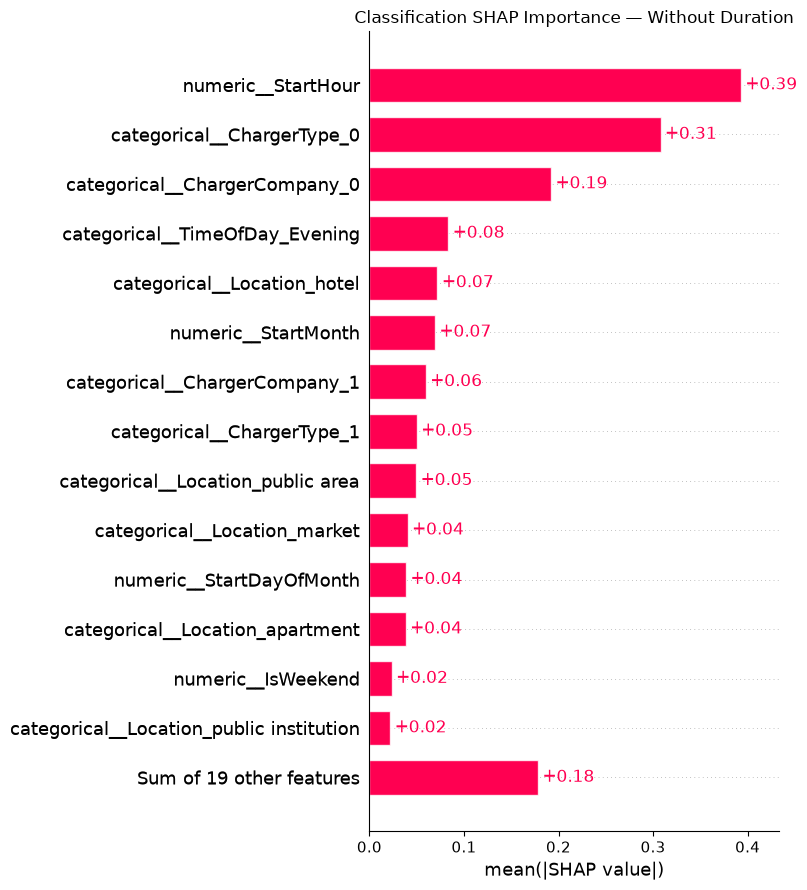

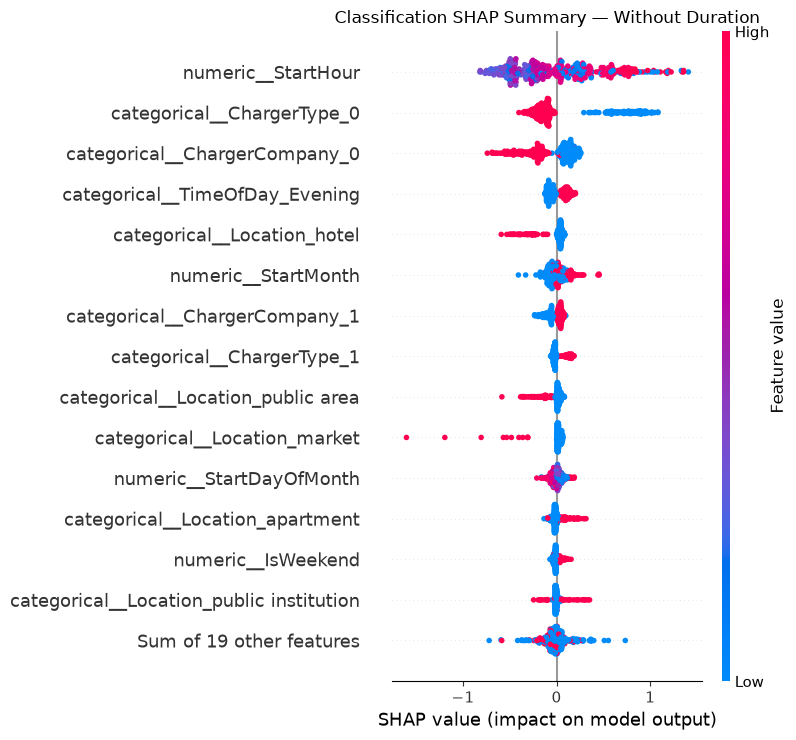


SHAP analysis: LightGBM — With Duration


,Feature,MeanAbsoluteSHAP
0,numeric__DurationValidated,2.7471
1,categorical__ChargerType_0,1.0680
2,categorical__ChargerType_1,0.3560
3,categorical__ChargerCompany_0,0.2432
4,numeric__StartHour,0.2037
5,numeric__StartMonth,0.1055
6,categorical__Location_resort,0.0710
7,categorical__ChargerCompany_1,0.0663
8,categorical__TimeOfDay_Evening,0.0639
9,categorical__Location_company,0.0568


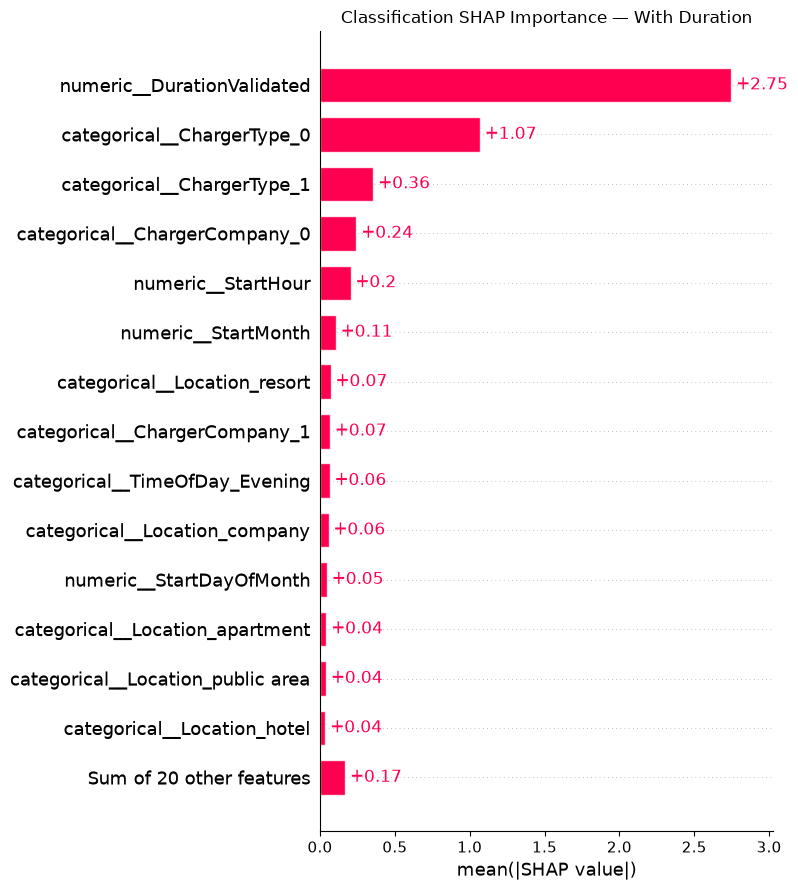

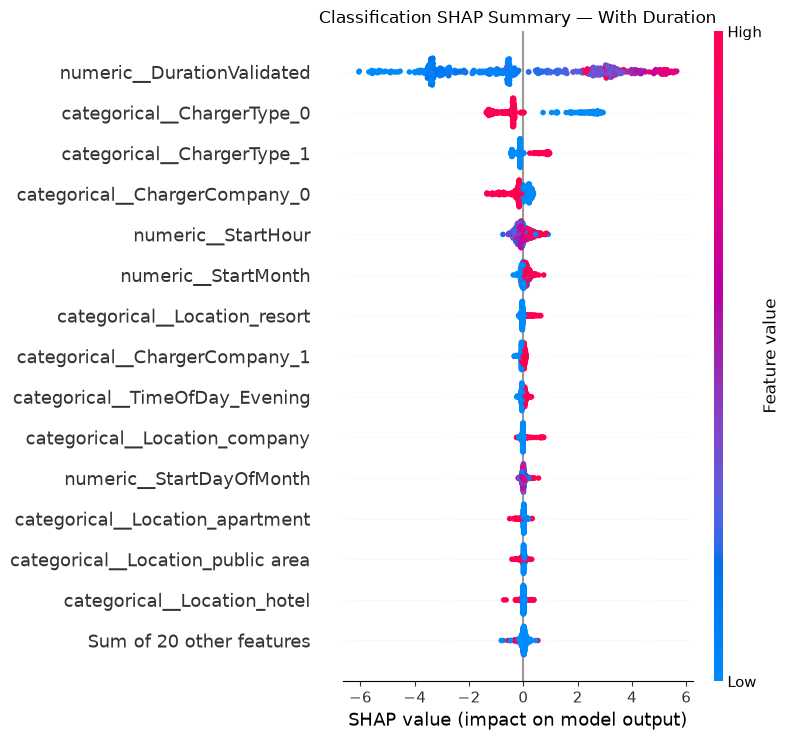


Classification SHAP analysis completed.


In [4]:
# SHAP explainability for the saved LightGBM classifiers

from pathlib import Path

import joblib
import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

MODELS_DIR = Path("../models")
REPORTS_DIR = Path("../reports")
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

# Analyze both existing models without retraining them.
classification_models = {
    "Without Duration": {
        "path": MODELS_DIR / "lightgbm_classifier_without_duration_pipeline.joblib",
        "X_test": X_test_without,
    },
    "With Duration": {
        "path": MODELS_DIR / "lightgbm_classifier_with_duration_pipeline.joblib",
        "X_test": X_test_with,
    },
}

classification_shap_results = {}

for model_name, config in classification_models.items():
    print(f"\nSHAP analysis: LightGBM — {model_name}")

    # Load the fitted preprocessing and classification pipeline.
    pipeline = joblib.load(config["path"])
    X_test_current = config["X_test"]

    preprocessor = pipeline.named_steps["preprocessor"]
    classifier = pipeline.named_steps["model"]

    # Use a reproducible sample to keep computation manageable.
    X_sample = X_test_current.sample(
        n=min(500, len(X_test_current)),
        random_state=42,
    )

    # Apply the preprocessing already fitted during model training.
    transformed = preprocessor.transform(X_sample)
    feature_names = preprocessor.get_feature_names_out()

    transformed_df = pd.DataFrame(
        transformed,
        columns=feature_names,
        index=X_sample.index,
    )

    # Explain the fitted LightGBM classifier.
    explainer = shap.TreeExplainer(classifier)
    shap_explanation = explainer(transformed_df)

    # Handle SHAP version differences for binary-classification output.
    # When separate outputs are returned, use class 1: High Demand.
    if isinstance(shap_explanation, list):
        shap_explanation = shap_explanation[1]

    elif np.asarray(shap_explanation.values).ndim == 3:
        # For output shaped (observations, features, classes),
        # select the High Demand class (label 1).
        shap_explanation = shap_explanation[:, :, 1]

    # Rank encoded features by their mean absolute SHAP values.
    shap_importance_df = pd.DataFrame({
        "Feature": transformed_df.columns,
        "MeanAbsoluteSHAP": np.abs(
            shap_explanation.values
        ).mean(axis=0),
    }).sort_values(
        "MeanAbsoluteSHAP",
        ascending=False,
    ).reset_index(drop=True)

    classification_shap_results[model_name] = {
        "importance": shap_importance_df,
        "explanation": shap_explanation,
        "sample": transformed_df,
    }

    display(shap_importance_df.head(15).round(4))

    suffix = model_name.lower().replace(" ", "_")

    # Save the complete numerical importance ranking.
    shap_importance_df.to_csv(
        REPORTS_DIR / f"classification_shap_importance_{suffix}.csv",
        index=False,
    )

    # SHAP global feature-importance bar plot.
    shap.plots.bar(
        shap_explanation,
        max_display=15,
        show=False,
    )
    plt.title(f"Classification SHAP Importance — {model_name}")
    plt.tight_layout()
    plt.savefig(
        REPORTS_DIR / f"classification_shap_bar_{suffix}.png",
        dpi=150,
        bbox_inches="tight",
    )
    plt.show()
    plt.close()

    # SHAP beeswarm plot: distribution and direction of contributions.
    shap.plots.beeswarm(
        shap_explanation,
        max_display=15,
        show=False,
    )
    plt.title(f"Classification SHAP Summary — {model_name}")
    plt.tight_layout()
    plt.savefig(
        REPORTS_DIR / f"classification_shap_summary_{suffix}.png",
        dpi=150,
        bbox_inches="tight",
    )
    plt.show()
    plt.close()

print("\nClassification SHAP analysis completed.")

In [5]:
# Confirm that the two saved tables contain different results.
shap_without = pd.read_csv(
    REPORTS_DIR / "classification_shap_importance_without_duration.csv"
)

shap_with = pd.read_csv(
    REPORTS_DIR / "classification_shap_importance_with_duration.csv"
)

print("WITHOUT duration — top feature:")
display(shap_without.head(5))

print("WITH duration — top feature:")
display(shap_with.head(5))

WITHOUT duration — top feature:


,Feature,MeanAbsoluteSHAP
0,numeric__StartHour,0.392933
1,categorical__ChargerType_0,0.307915
2,categorical__ChargerCompany_0,0.192239
3,categorical__TimeOfDay_Evening,0.083491
4,categorical__Location_hotel,0.072011


WITH duration — top feature:


,Feature,MeanAbsoluteSHAP
0,numeric__DurationValidated,2.747138
1,categorical__ChargerType_0,1.067959
2,categorical__ChargerType_1,0.355979
3,categorical__ChargerCompany_0,0.243182
4,numeric__StartHour,0.203686


## Classification SHAP Analysis — Findings and Limitations

SHAP (SHapley Additive exPlanations) was used to examine the saved LightGBM classification pipelines, with and without `DurationValidated`. The analysis used transformed features from the fitted preprocessing pipelines and a sample of the chronological test data. Mean absolute SHAP values were used to rank features by their average contribution magnitude.

### 1. LightGBM without duration

The leading features were:

- `StartHour`: 0.3929
- `ChargerType_0`: 0.3079
- `ChargerCompany_0`: 0.1922
- `TimeOfDay_Evening`: 0.0835
- `Location_hotel`: 0.0720

**Finding:** Start hour was the most influential feature by mean absolute SHAP, followed by encoded charger type and company categories. This suggests that temporal and charger-related information contributes substantially to the model's High Demand versus Normal Demand predictions.

### 2. LightGBM with duration

The leading features were:

- `DurationValidated`: 2.7471
- `ChargerType_0`: 1.0680
- `ChargerType_1`: 0.3560
- `ChargerCompany_0`: 0.2432
- `StartHour`: 0.2037

**Finding:** Validated duration was the dominant feature in the duration-informed classifier. The summary plot generally shows higher duration values contributing positively to the model output for High Demand and lower values contributing negatively.

However, actual duration is only known after a charging session. Therefore, this model must not be presented as a genuine session-start prediction model. Use the duration-free classifier when making predictions at session start. Any user-supplied duration estimate must be explicitly identified as an estimate.

### 3. Interpretation and limitations

- Mean absolute SHAP measures average contribution magnitude; it does not show causality.
- SHAP values represent contributions to the model output, not direct percentage-point changes in predicted probability.
- Encoded labels such as `ChargerType_0` and `ChargerCompany_0` are category indicators. Their real-world meanings cannot be established without the relevant category mapping.
- The results describe these fitted models and this test sample; they should not be assumed to generalize perfectly to every charging station or future period.

### 4. Explainability status

Regression permutation importance and SHAP, as well as classification SHAP, have been completed for the current project scope. LIME was intentionally skipped to prioritize delivery and testing of the application. Since LIME is listed in the GUVI brief, its omission must be disclosed as a project limitation.

### Conclusion

The duration-free classifier relies most strongly on starting hour and charger-related categories, while the duration-informed classifier relies heavily on `DurationValidated`. These results support using the duration-free model for the session-start scenario and clearly separating it from duration-informed predictions.
